In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np

train_dir = "./data/Training Data/Training Data"
val_dir = "./data/Validation Data/Validation Data"
test_dir = "./data/Testing Data/Testing Data"

C:\Users\Hp\AppData\Local\Temp\ipykernel_8180\2391739529.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_counts.sort_values('Count', ascending=False), x='Animal', y='Count', palette='viridis')


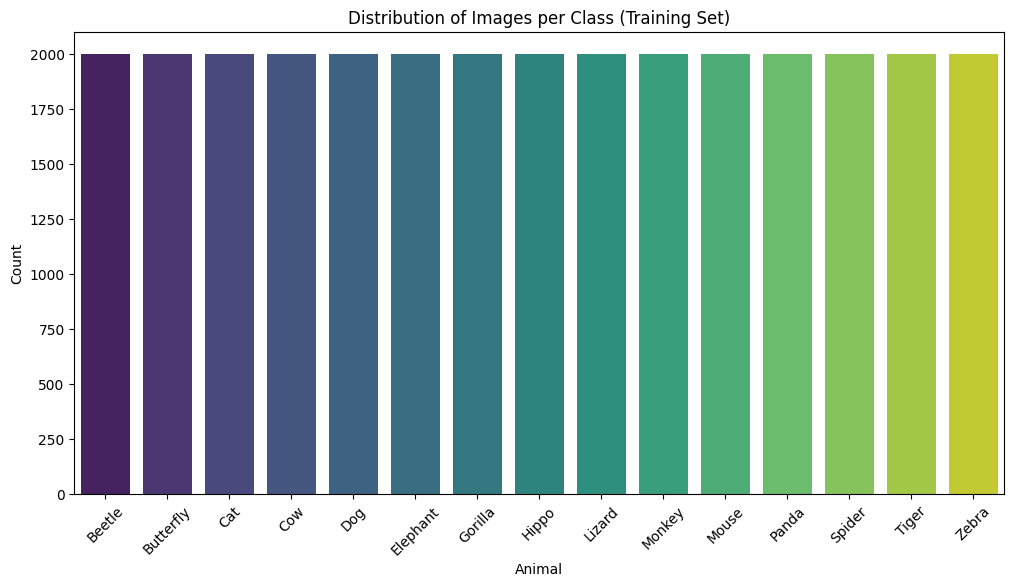

In [5]:
def get_class_counts(directory):
    classes = os.listdir(directory)
    counts = {cls: len(os.listdir(os.path.join(directory, cls))) for cls in classes}
    return counts

train_counts = get_class_counts(train_dir)
df_counts = pd.DataFrame(list(train_counts.items()), columns=['Animal', 'Count'])

plt.figure(figsize=(12, 6))
sns.barplot(data=df_counts.sort_values('Count', ascending=False), x='Animal', y='Count', palette='viridis')
plt.title('Distribution of Images per Class (Training Set)')
plt.xticks(rotation=45)
plt.show()

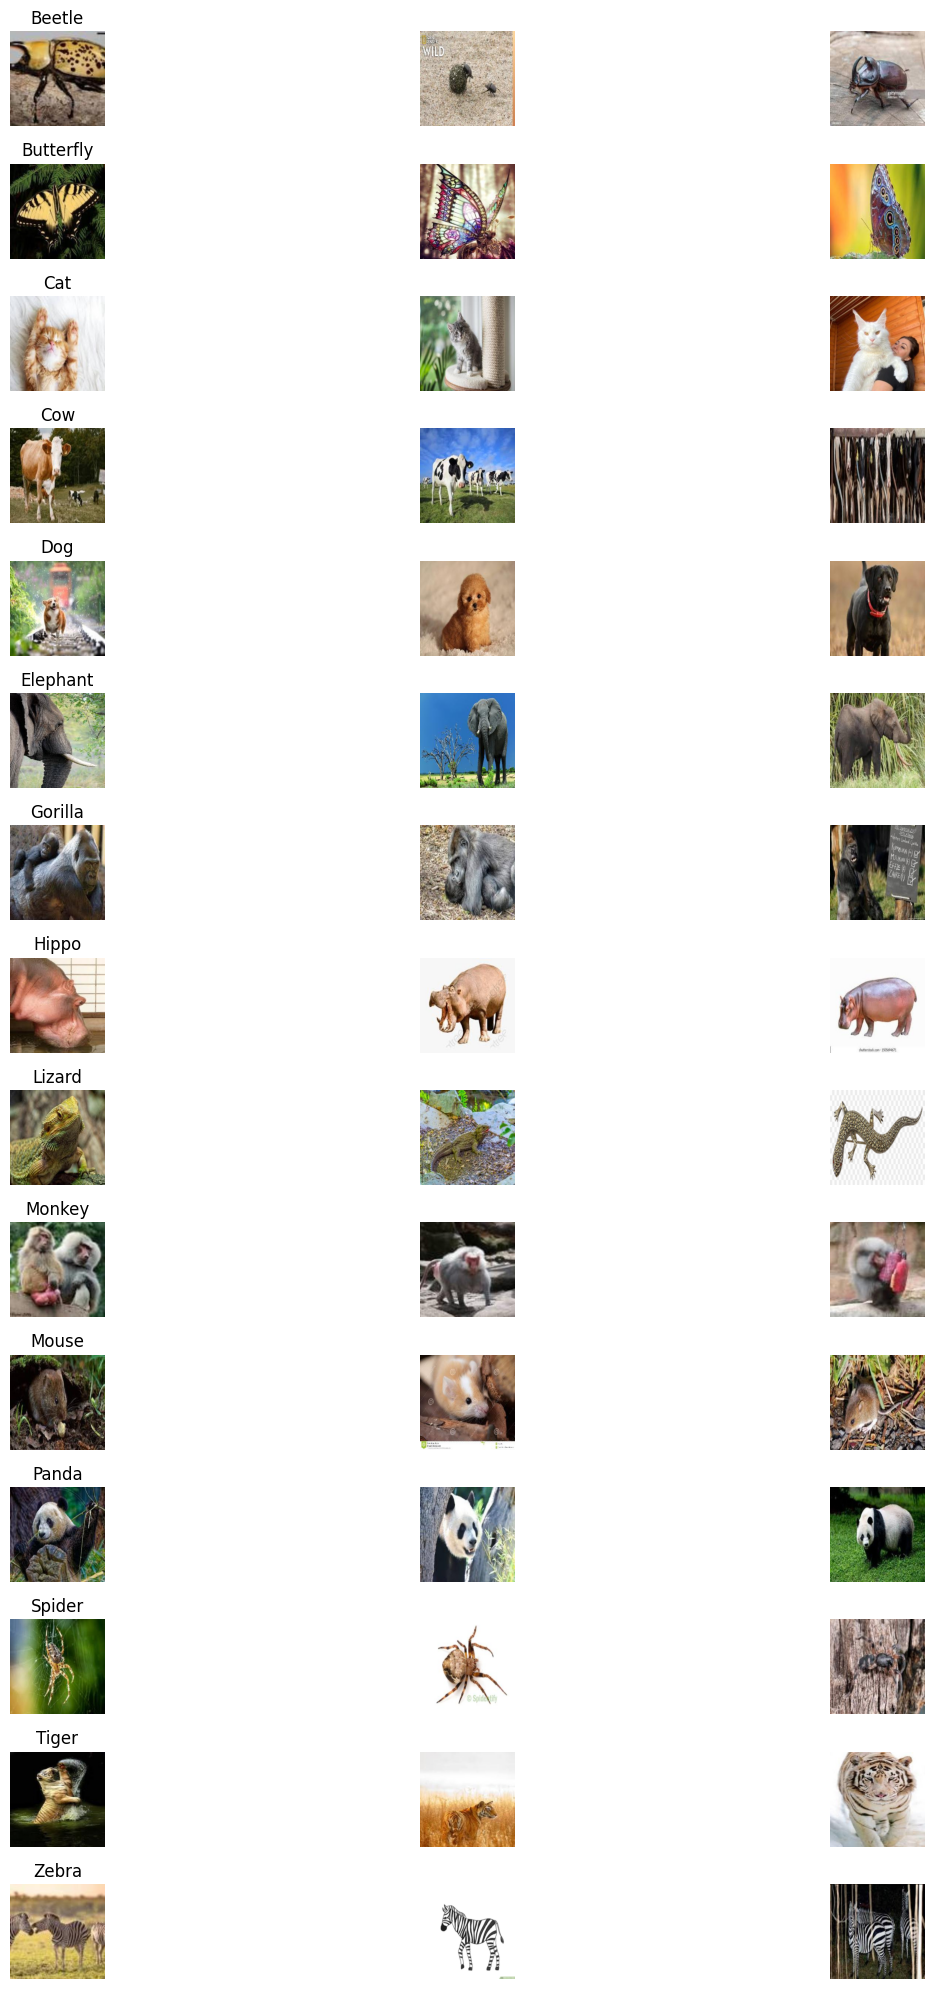

In [6]:
def plot_sample_images(root_path, n_samples=3):
    classes = os.listdir(root_path)
    fig, axes = plt.subplots(len(classes), n_samples, figsize=(15, 20))
    
    for i, cls in enumerate(classes):
        cls_path = os.path.join(root_path, cls)
        img_names = os.listdir(cls_path)[:n_samples]
        for j, img_name in enumerate(img_names):
            img = Image.open(os.path.join(cls_path, img_name))
            axes[i, j].imshow(img)
            axes[i, j].set_title(cls if j == 0 else "")
            axes[i, j].axis('off')
    plt.tight_layout()
    plt.show()

plot_sample_images(train_dir)

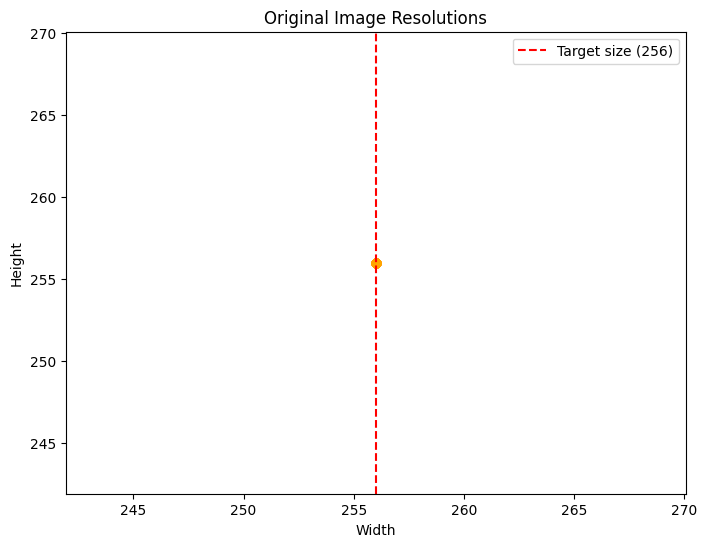

In [7]:
widths, heights = [], []
for cls in os.listdir(train_dir)[:3]:
    cls_path = os.path.join(train_dir, cls)
    for img_name in os.listdir(cls_path)[:50]:
        with Image.open(os.path.join(cls_path, img_name)) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)

plt.figure(figsize=(8, 6))
plt.scatter(widths, heights, alpha=0.5, color='orange')
plt.xlabel('Width')
plt.ylabel('Height')
plt.title('Original Image Resolutions')
plt.axvline(256, color='red', linestyle='--', label='Target size (256)')
plt.legend()
plt.show()

Max pixel value: 255
Min pixel value: 0
Mean pixel value: 111.91


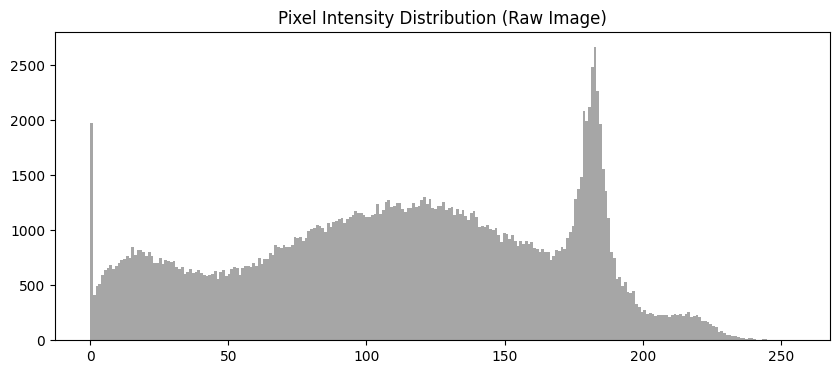

In [8]:
sample_cls = os.listdir(train_dir)[0]
sample_img_path = os.path.join(train_dir, sample_cls, os.listdir(os.path.join(train_dir, sample_cls))[0])
img_array = np.array(Image.open(sample_img_path))

print(f"Max pixel value: {img_array.max()}")
print(f"Min pixel value: {img_array.min()}")
print(f"Mean pixel value: {img_array.mean():.2f}")

plt.figure(figsize=(10, 4))
plt.hist(img_array.ravel(), bins=256, color='gray', alpha=0.7)
plt.title('Pixel Intensity Distribution (Raw Image)')
plt.show()